## Scenario: Student Dropout Prediction

The university wants to identify students who might drop out.

### Features
- GPA
- Major
- Number of clubs joined
- Attendance percentage

### Target Variable
- **Dropout**: 1 = Yes, 0 = No

### Data Generation Plan
1. **Distributions**
   - GPA: Normal distribution (mean ≈ 3.0, std ≈ 0.5).
   - Major: Randomly chosen from: Computer Science, Math, Economics, History
   - Clubs: Poisson distribution (average = 2 clubs).
   - Attendance: Uniform distribution between 50% and 100%.

2. **Dropout Rules**
   - GPA < 2.5 and Attendance < 70% → High dropout probability





    GPA    Major  Clubs  Attendance  Dropout
0  3.25     Math      4        82.6        0
1  2.93     Math      0        91.5        0
2  3.32       CS      0        60.3        0
3  3.76  History      0        50.5        0
4  2.88       CS      0        56.8        0
              GPA       Clubs  Attendance     Dropout
count  200.000000  200.000000  200.000000  200.000000
mean     2.979850    1.890000   75.700500    0.075000
std      0.465502    1.399174   14.900418    0.264052
min      1.690000    0.000000   50.500000    0.000000
25%      2.647500    1.000000   61.850000    0.000000
50%      2.995000    2.000000   76.150000    0.000000
75%      3.252500    3.000000   89.075000    0.000000
max      4.360000    8.000000   99.900000    1.000000
Dropout
0    185
1     15
Name: count, dtype: int64
Major
CS           2.988571
Economics    2.943500
History      2.954464
Math         3.024364
Name: GPA, dtype: float64
     GPA      Major  Clubs  Attendance  Dropout
13  2.04       Math     

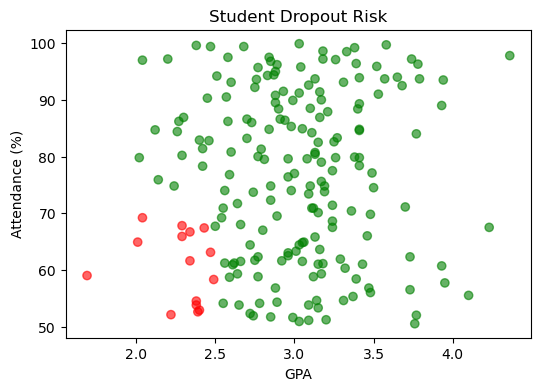

In [10]:
# Generating the Data
import numpy as np
import pandas as pd
np.random.seed(42)
n = 200
gpa = np.round(np.random.normal(3.0, 0.5, n), 2)
majors = np.random.choice(['CS', 'Math', 'Economics', 'History'], n)
clubs = np.random.poisson(2, n)
attendance = np.random.uniform(50, 100, n)


# Dropout rule (target variable)
dropout_prob = (gpa < 2.5) & (attendance < 70)
dropout = np.where(dropout_prob, 1, 0)


#Create DataFrame
df = pd.DataFrame({
    'GPA': gpa,
    'Major': majors,
    'Clubs': clubs,
    'Attendance': np.round(attendance, 1),
    'Dropout': dropout
})

print(df.head())

print(df.describe())

print(df['Dropout'].value_counts())

print(df.groupby('Major')['GPA'].mean())

#Identify high-risk students
high_risk = df[(df['GPA'] < 2.5) & (df['Attendance'] < 70)]
print(high_risk.head())

#Dropout rate by major
dropout_rate_by_major = df.groupby('Major')['Dropout'].mean().sort_values(ascending=False)
print("Dropout rate by major:")
print(dropout_rate_by_major)

# Compare summary stats for dropouts vs non-dropouts
print("Summary statistics for dropouts:")
print(df[df['Dropout'] == 1].describe())

print("\nSummary statistics for non-dropouts:")
print(df[df['Dropout'] == 0].describe())


import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
colors = df['Dropout'].map({0: 'green', 1: 'red'})
plt.scatter(df['GPA'], df['Attendance'], c=colors, alpha=0.6)
plt.xlabel("GPA")
plt.ylabel("Attendance (%)")
plt.title("Student Dropout Risk")
plt.show()





#### Assignment Report: Student Dropout Prediction


Findings
- *Low GPA (<2.5) and low attendance (<70%)* are strongly associated with dropout.  
- Certain majors may show slightly higher dropout rates ( Economics > History > MAths > CS).  
- Students with **more clubs** tend to have lower probabilty of dropout 

##### Action Items
1. *Academic Support Program*:  
   Provide targeted tutoring and mentoring for students with GPA < 2.5 before they fall into the “at risk” category.  

2. *Attendance Monitoring & Alerts*:  
   Set up warning system that flags students with <70% attendance and prompting timely interventions such as counseling or faculty check-ins.  

---

#### 2. Simulated Problem: Broader Student Retention Analysis

##### Scenario Setup
A larger dataset is assumed to include:
- Academic features: GPA, Attendance, Major, Clubs  
- Additional features: **family background, financial aid status, commuting distance, and mental health survey scores**  
- Dropout risk is driven not only by GPA and attendance, but also by financial stress and lack of social engagement.  

##### Detailed Analysis
- *Academic Factors*: GPA <2.5 and Attendance <70% show strong correlation with dropout.  
- *Financial Factors*: Students without scholarships/aid are more likely to drop out, especially in expensive majors.  
- *Engagement*: Lack of participation in clubs or on-campus activities increases dropout risk.  
- *Well-being*: Students with low mental health scores face higher dropout risk, even when GPA is strong.  

##### Action Items
1. *Comprehensive Student Support System*  
   Establish an integrated support hub combining **academic advising, financial aid counseling, and mental health services**. Students with multiple risk factors (low GPA, low aid, low mental health scores) should be proactively contacted.  

2. *Peer Mentorship & Engagement Programs*  
   Expand clubs, peer mentoring, and career workshops to strengthen student engagement. Encourage at-risk students to participate in at least one extracurricular activity to reduce dropout probability.  


### Simulated Problem

Generate a  database Restaurnt Manu with unit sold and revenue  

Identify the underperforming dish  
 1. unit sold < 5
 2. Revenue < 20  

create new after exculding the underperforming dish


In [11]:
import pandas as pd
import numpy as np

# Define menu items
menu = [
    {"Item Name": "Vegetable Coriander Soup", "Category": "Soup", "Price": 5.0},
    {"Item Name": "Cream of Tomato Soup", "Category": "Soup", "Price": 5.5},
    {"Item Name": "Hot & Sour Soup (Veg)", "Category": "Soup", "Price": 6.0},
    {"Item Name": "Hot & Sour Soup (Non-Veg)", "Category": "Soup", "Price": 7.0},
    {"Item Name": "Cream of Chicken Soup", "Category": "Soup", "Price": 6.5},
    {"Item Name": "Consommé Soup", "Category": "Soup", "Price": 7.5},
    {"Item Name": "Pasta Alfredo", "Category": "Main Course", "Price": 12.0},
    {"Item Name": "Grilled Chicken", "Category": "Main Course", "Price": 15.0},
    {"Item Name": "Veg Burger", "Category": "Snack", "Price": 8.0},
    {"Item Name": "Chicken Burger", "Category": "Snack", "Price": 9.0}
]

# Generate sales data for 30 days
dates = pd.date_range(start="2025-09-01", periods=30)
data = []

np.random.seed(42)  # For reproducibility

for date in dates:
    for item in menu:
        # Units sold follow a Poisson distribution, mean varies slightly by item
        mean_sales = np.random.randint(5, 20)
        units_sold = np.random.poisson(mean_sales)
        revenue = units_sold * item["Price"]
        data.append({
            "Date": date,
            "Item Name": item["Item Name"],
            "Category": item["Category"],
            "Price": item["Price"],
            "Units Sold": units_sold,
            "Revenue": revenue
        })

# Create DataFrame
df = pd.DataFrame(data)

# Show the first few rows
print(df.head())

# Summary statistics
print(df.describe())


        Date                  Item Name Category  Price  Units Sold  Revenue
0 2025-09-01   Vegetable Coriander Soup     Soup    5.0          14     70.0
1 2025-09-01       Cream of Tomato Soup     Soup    5.5          13     71.5
2 2025-09-01      Hot & Sour Soup (Veg)     Soup    6.0           5     30.0
3 2025-09-01  Hot & Sour Soup (Non-Veg)     Soup    7.0          16    112.0
4 2025-09-01      Cream of Chicken Soup     Soup    6.5          12     78.0
                      Date       Price  Units Sold     Revenue
count                  300  300.000000  300.000000  300.000000
mean   2025-09-15 12:00:00    8.150000   11.936667   97.063333
min    2025-09-01 00:00:00    5.000000    1.000000    5.500000
25%    2025-09-08 00:00:00    6.000000    8.000000   56.000000
50%    2025-09-15 12:00:00    7.250000   11.000000   84.250000
75%    2025-09-23 00:00:00    9.000000   16.000000  127.500000
max    2025-09-30 00:00:00   15.000000   29.000000  375.000000
std                    NaN    2.98

In [12]:
# Identify underperforming items (units sold < 5 AND revenue < 20)
underperforming_items = df[(df['Units Sold'] < 5) & (df['Revenue'] < 20)]

# Display the underperforming items
print("Underperforming Items (Units Sold < 5 AND Revenue < 20):")
display(underperforming_items)

Underperforming Items (Units Sold < 5 AND Revenue < 20):


,Date,Item Name,Category,Price,Units Sold,Revenue
52,2025-09-06,Hot & Sour Soup (Veg),Soup,6.0,3,18.0
61,2025-09-07,Cream of Tomato Soup,Soup,5.5,3,16.5
93,2025-09-10,Hot & Sour Soup (Non-Veg),Soup,7.0,2,14.0
109,2025-09-11,Chicken Burger,Snack,9.0,2,18.0
184,2025-09-19,Cream of Chicken Soup,Soup,6.5,3,19.5
204,2025-09-21,Cream of Chicken Soup,Soup,6.5,3,19.5
221,2025-09-23,Cream of Tomato Soup,Soup,5.5,1,5.5
240,2025-09-25,Vegetable Coriander Soup,Soup,5.0,3,15.0
259,2025-09-26,Chicken Burger,Snack,9.0,2,18.0
260,2025-09-27,Vegetable Coriander Soup,Soup,5.0,3,15.0


In [13]:
# Remove underperforming items (units sold < 5) from the DataFrame
df_sales_filtered = df[(df['Units Sold'] >= 5) & (df['Revenue'] >= 20)].copy()

# Display the head of the filtered DataFrame to show the change
print("DataFrame after removing underperforming items:")
display(df_sales_filtered.head())

DataFrame after removing underperforming items:


,Date,Item Name,Category,Price,Units Sold,Revenue
0,2025-09-01,Vegetable Coriander Soup,Soup,5.0,14,70.0
1,2025-09-01,Cream of Tomato Soup,Soup,5.5,13,71.5
2,2025-09-01,Hot & Sour Soup (Veg),Soup,6.0,5,30.0
3,2025-09-01,Hot & Sour Soup (Non-Veg),Soup,7.0,16,112.0
4,2025-09-01,Cream of Chicken Soup,Soup,6.5,12,78.0
